# iLQR: swinging up a torque-limited pendulum

This notebook solves a non-linear optimal control problem with the **iterative LQR** solver `diffilqrax.ilqr.ilqr_solver`. A pendulum starts hanging down and must be swung up to the upright position within $T\,\delta t = 5$ s. The motor cannot lift it directly, because the torque limit is smaller than $mgl$, so the solver has to discover a pumping strategy.

**Dynamics.** With angle $\phi$ measured from hanging down,

$$
\ddot\phi = -\frac{g}{l}\sin\phi - b\,\dot\phi + \frac{u}{m l^2},
$$

discretised with an Euler step. The state is $x = (\phi, \dot\phi)$.

**Cost.** There is a small running cost on being away from upright, on velocity and on torque, plus a smooth barrier that keeps $|u| \lesssim u_{\max}$. A large terminal cost asks for upright ($\phi = \pm\pi$) and still.

**How iLQR works.** Each iteration takes the current trajectory $(\bar x, \bar u)$ and forms a local LQR problem from first-order dynamics and second-order cost expansions. These are computed with `jax.jacfwd`/`jax.hessian`, so no hand-written derivatives are needed. The solver then:

1. solves the local LQR with a Riccati backward pass, adding Levenberg–Marquardt regularisation to the input Hessian until it is positive definite;
2. rolls out the non-linear dynamics under the new feedback policy $u_t = \bar u_t + \alpha k_t + K_t(x_t - \bar x_t)$, choosing $\alpha$ with an Armijo line search.

It stops when the input gradient of the Lagrangian $\max_t|\partial L/\partial u_t|$ falls below `kkt_tol`.

In [1]:
import jax
import jax.numpy as jnp
import jax.random as jr
import matplotlib.pyplot as plt

from diffilqrax.ilqr import ilqr_solver, ilqr_simulate, approx_lqr, kkt_input_residual
from diffilqrax.typs import System, ModelDims, iLQRParams, PendulumParams

jax.config.update("jax_enable_x64", True)

## Defining the model

A `diffilqrax.typs.System` bundles three functions and the problem dimensions:

- `cost(t, x, u, theta)` is the running cost,
- `costf(x, theta)` is the terminal cost,
- `dynamics(t, x, u, theta)` returns $x_{t+1}$.

`theta` can be any pytree of parameters. Here it is a `PendulumParams(m, l, g)`. Keeping parameters in `theta` instead of hard-coding them is what makes them differentiable later (see [gradients through iLQR](gradients_through_ilqr.ipynb)).

In [2]:
DT, DAMPING, U_MAX, HORIZON = 0.05, 0.1, 3.0, 100
dims = ModelDims(n=2, m=1, horizon=HORIZON, dt=DT)


def dynamics(t, x, u, theta):
    """Euler step; x = [angle, angular velocity], angle 0 is hanging down"""
    acc = -theta.g / theta.l * jnp.sin(x[0]) - DAMPING * x[1] + u[0] / (theta.m * theta.l**2)
    return x + DT * jnp.stack([x[1], acc])


def cost(t, x, u, theta):
    """Small running cost on angle, velocity and torque, plus a smooth barrier at |u| = U_MAX"""
    barrier = jax.nn.softplus(5.0 * (u - U_MAX)) ** 2 + jax.nn.softplus(5.0 * (-u - U_MAX)) ** 2
    return 0.1 * (1.0 + jnp.cos(x[0])) + 0.01 * x[1] ** 2 + 0.01 * jnp.sum(u**2) + jnp.sum(barrier)


def costf(x, theta):
    """Be upright (angle ±pi) and still at the final time"""
    return 50.0 * (1.0 + jnp.cos(x[0])) + 5.0 * x[1] ** 2


model = System(cost, costf, dynamics, dims)
params = iLQRParams(x0=jnp.array([0.1, 0.0]), theta=PendulumParams(m=1.0, l=1.0, g=9.8))
Us_init = 0.5 * jr.normal(jr.PRNGKey(0), (HORIZON, 1))
time = jnp.arange(HORIZON + 1) * DT

## Solving

The solver returns `((Xs, Us, lambdas), total_cost, cost_history)`. `cost_history` has length
`max_iter`; after convergence its entries stay constant at the final cost.

In [3]:
(Xs, Us, lambdas), total_cost, cost_log = ilqr_solver(model, params, Us_init, max_iter=300)

(X_init, _), J_init = ilqr_simulate(model, Us_init, params)
residual = kkt_input_residual(approx_lqr(model, Xs, Us, params))
print(f"cost: {float(J_init):.3f} (initial) -> {float(total_cost):.3f} (optimal)")
print(f"max|dL/du| = {jnp.max(jnp.abs(residual)):.1e}")
print(f"final angle {float(Xs[-1, 0]):.3f} rad (upright = ±{jnp.pi:.3f}), max|u| = {float(jnp.abs(Us).max()):.2f}")

cost: 118.408 (initial) -> 17.897 (optimal)
max|dL/du| = 8.7e-11
final angle -3.140 rad (upright = ±3.142), max|u| = 2.52


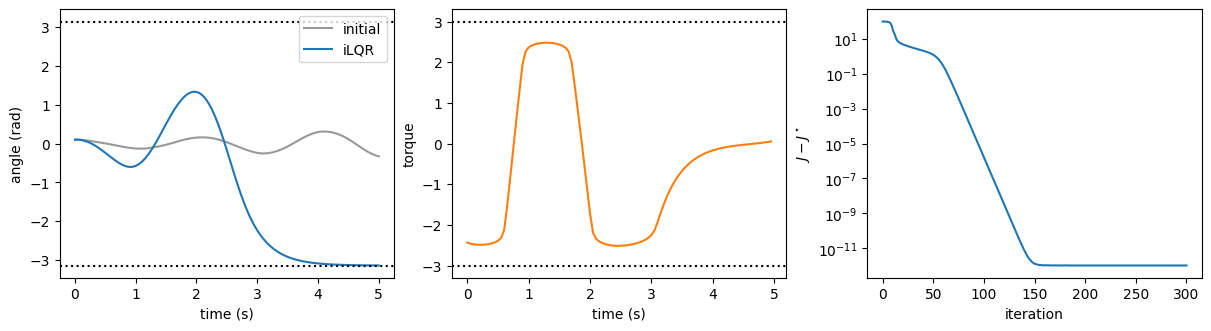

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), layout="constrained")
axes[0].plot(time, X_init[:, 0], c="0.6", label="initial")
axes[0].plot(time, Xs[:, 0], c="C0", label="iLQR")
for s in (-1, 1):
    axes[0].axhline(s * jnp.pi, ls=":", c="k")
axes[0].set(xlabel="time (s)", ylabel="angle (rad)")
axes[0].legend()
axes[1].plot(time[:-1], Us[:, 0], c="C1")
for s in (-1, 1):
    axes[1].axhline(s * U_MAX, ls=":", c="k")
axes[1].set(xlabel="time (s)", ylabel="torque")
axes[2].semilogy(cost_log - cost_log.min() + 1e-12)
axes[2].set(xlabel="iteration", ylabel=r"$J - J^\star$");

The torque limit is well below $mgl$, so the solver discovers a pump: it swings one way, then
the other, and finally over the top, all while staying within the limit. The cost drops by most of
its initial value within the first ~20 iterations. After that the solver converges linearly down to
the round-off level of the cost. The default first trial step is
$\alpha = \tau \cdot \texttt{alpha\_init} = 0.5$, which is cautious but robust.

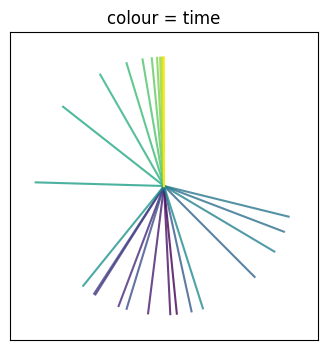

In [5]:
fig, ax = plt.subplots(figsize=(4, 4))
for i in range(0, HORIZON + 1, 4):
    px, py = jnp.sin(Xs[i, 0]), -jnp.cos(Xs[i, 0])
    ax.plot([0, px], [0, py], c=plt.cm.viridis(i / HORIZON), alpha=0.8)
ax.set(aspect="equal", xlim=(-1.2, 1.2), ylim=(-1.2, 1.2), xticks=[], yticks=[], title="colour = time");

## How to adapt

- **Your own system:** replace `dynamics` with any differentiable JAX function of `(t, x, u, theta)` and update `ModelDims(n, m, horizon, dt)`. For stiff or fast dynamics, use a better integrator (for example RK4) inside `dynamics`.
- **Costs:** any twice-differentiable scalar function works. Use smooth penalties (softplus, as here) for limits, because hard `clip`/`max` have zero curvature and slow iLQR down.
- **Initial guess:** iLQR is a local method. A non-zero `Us_init` (here a little noise) can break symmetries, and a feasible heuristic speeds up hard problems.
- **Convergence:** `kkt_tol` (default `1e-10`) sets the stopping test and `max_iter` caps the iterations. Line-search options (`tau`, `beta`, `alpha_min`, `max_iter_linesearch`) are passed through as keyword arguments. `alpha_init=2.0` makes the first trial a full Newton step ($\alpha = 1$).
- **Compile once, solve many:** wrap the call in `jax.jit` (with `model` closed over) when solving repeatedly, for example in MPC or in a training loop.